# CONFIG PACKAGE

In [92]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sqlalchemy import create_engine


from utils.config import DB_CONFIG
from utils.cleaning import *
from utils.db import *

# KET NOI DATABASE

In [93]:
engine = make_engine(DB_CONFIG) # sử dụng def make_engine(config) trong utils/db.py để tạo engine kết nối đến database
test_connection(engine) # sử dụng def test_connection(engine) trong utils/db.py để kiểm tra kết nối đến database

Connected — MySQL 8.0.46


In [94]:
query = """
select t2.orderNumber,
		t2.orderDate,
        t2.shippedDate,
        t2.status as orderStatus,
        t3.customerNumber,
        t3.customerName,
        t3.country as customerCountry,
        t3.city as customerCity,
        t3.creditLimit,
        concat(t4.firstName, ' ', t4.lastName) as salesRep,
        t5.productName,
        t5.productLine,
        t5.quantityInStock,
        t1.quantityOrdered,
        t1.priceEach,
        t1.quantityOrdered * t1.priceEach as lineRevenue
from orderdetails t1
join orders t2 on t1.orderNumber = t2.orderNumber
join customers t3 on t2.customerNumber = t3.customerNumber
join employees t4 on t3.salesRepEmployeeNumber = t4.employeeNumber
join products t5 on t1.productCode = t5.productCode;
"""

df = load_main_dataset(query, engine) 
df.head()

,orderNumber,orderDate,shippedDate,orderStatus,customerNumber,customerName,customerCountry,customerCity,creditLimit,salesRep,productName,productLine,quantityInStock,quantityOrdered,priceEach,lineRevenue
0,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1917 Grand Touring Sedan,Vintage Cars,2724,30,136.00,4080.00
1,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1911 Ford Town Car,Vintage Cars,540,50,55.09,2754.50
2,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1932 Alfa Romeo 8C2300 Spider Sport,Vintage Cars,6553,22,75.46,1660.12
3,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1936 Mercedes Benz 500k Roadster,Vintage Cars,2081,49,35.29,1729.21
4,10101,2003-01-09,2003-01-11,Shipped,128,"Blauer See Auto, Co.",Germany,Frankfurt,59700.0,Barry Jones,1932 Model A Ford J-Coupe,Vintage Cars,9354,25,108.06,2701.50


# CHUNKED DATA

In [95]:
df_chunked = load_main_dataset_chunked(query, engine, chunksize = 1000)
df_chunked.head()

  chunk 01: 1000 rows
  chunk 02: 1000 rows
  chunk 03: 996 rows
  total : 2,996 rows


,orderNumber,orderDate,shippedDate,orderStatus,customerNumber,customerName,customerCountry,customerCity,creditLimit,salesRep,productName,productLine,quantityInStock,quantityOrdered,priceEach,lineRevenue
0,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1917 Grand Touring Sedan,Vintage Cars,2724,30,136.00,4080.00
1,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1911 Ford Town Car,Vintage Cars,540,50,55.09,2754.50
2,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1932 Alfa Romeo 8C2300 Spider Sport,Vintage Cars,6553,22,75.46,1660.12
3,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1936 Mercedes Benz 500k Roadster,Vintage Cars,2081,49,35.29,1729.21
4,10101,2003-01-09,2003-01-11,Shipped,128,"Blauer See Auto, Co.",Germany,Frankfurt,59700.0,Barry Jones,1932 Model A Ford J-Coupe,Vintage Cars,9354,25,108.06,2701.50


# KIEM TRA TYPE DU LIEU

In [96]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2996 entries, 0 to 2995
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   orderNumber      2996 non-null   int64  
 1   orderDate        2996 non-null   object 
 2   shippedDate      2855 non-null   object 
 3   orderStatus      2996 non-null   str    
 4   customerNumber   2996 non-null   int64  
 5   customerName     2996 non-null   str    
 6   customerCountry  2996 non-null   str    
 7   customerCity     2996 non-null   str    
 8   creditLimit      2996 non-null   float64
 9   salesRep         2996 non-null   str    
 10  productName      2996 non-null   str    
 11  productLine      2996 non-null   str    
 12  quantityInStock  2996 non-null   int64  
 13  quantityOrdered  2996 non-null   int64  
 14  priceEach        2996 non-null   float64
 15  lineRevenue      2996 non-null   float64
dtypes: float64(3), int64(4), object(2), str(7)
memory usage: 374.6+ KB


In [97]:
df["orderDate"] = pd.to_datetime(df["orderDate"])
df["shippedDate"] = pd.to_datetime(df["shippedDate"])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2996 entries, 0 to 2995
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype        
---  ------           --------------  -----        
 0   orderNumber      2996 non-null   int64        
 1   orderDate        2996 non-null   datetime64[s]
 2   shippedDate      2855 non-null   datetime64[s]
 3   orderStatus      2996 non-null   str          
 4   customerNumber   2996 non-null   int64        
 5   customerName     2996 non-null   str          
 6   customerCountry  2996 non-null   str          
 7   customerCity     2996 non-null   str          
 8   creditLimit      2996 non-null   float64      
 9   salesRep         2996 non-null   str          
 10  productName      2996 non-null   str          
 11  productLine      2996 non-null   str          
 12  quantityInStock  2996 non-null   int64        
 13  quantityOrdered  2996 non-null   int64        
 14  priceEach        2996 non-null   float64      
 15  lineRevenue    

# OPTIMIZE BỘ NHỚ

In [98]:
print(df.memory_usage(deep=True).sum()/1024**2)

1.4446001052856445


In [99]:
# Trước khi optimization
mb_before = df.memory_usage(deep=True).sum()/1024**2
print(f"Memory usage before optimization: {mb_before:.2f} MB")

# Optimization
df = optimize_dtypes(df)

# Sau khi optimization
mb_after = df.memory_usage(deep=True).sum()/1024**2
print(f"Memory usage after optimization: {mb_after:.2f} MB")

Memory usage before optimization: 1.44 MB


Memory usage after optimization: 0.14 MB


# CHECK QUALITY CỦA DATAFRAME

In [100]:
qr = quality_report(df)
qr

,dtype,missing,missing%,unique,sample
column,,,,,
shippedDate,datetime64[s],141,4.7,247,2003-01-10 00:00:00
orderNumber,int16,0,0.0,326,10100
orderDate,datetime64[s],0,0.0,265,2003-01-06 00:00:00
orderStatus,category,0,0.0,6,Shipped
customerNumber,int16,0,0.0,98,363
customerName,category,0,0.0,98,Online Diecast Creations Co.
customerCountry,category,0,0.0,22,USA
customerCity,category,0,0.0,78,Nashua
creditLimit,float32,0,0.0,92,114200.0


In [101]:
missing = df["shippedDate"].isnull()
df[missing].head()

,orderNumber,orderDate,shippedDate,orderStatus,customerNumber,customerName,customerCountry,customerCity,creditLimit,salesRep,productName,productLine,quantityInStock,quantityOrdered,priceEach,lineRevenue
595,10167,2003-10-23,NaT,Cancelled,448,Scandinavian Gift Ideas,Sweden,Bräcke,116400.0,Barry Jones,1972 Alfa Romeo GTA,Classic Cars,3252,44,123.760002,5445.439941
596,10167,2003-10-23,NaT,Cancelled,448,Scandinavian Gift Ideas,Sweden,Bräcke,116400.0,Barry Jones,1980s Black Hawk Helicopter,Planes,5330,43,141.919998,6102.560059
597,10167,2003-10-23,NaT,Cancelled,448,Scandinavian Gift Ideas,Sweden,Bräcke,116400.0,Barry Jones,1999 Yamaha Speed Boat,Ships,4259,46,69.680000,3205.280029
598,10167,2003-10-23,NaT,Cancelled,448,Scandinavian Gift Ideas,Sweden,Bräcke,116400.0,Barry Jones,1941 Chevrolet Special Deluxe Cabriolet,Vintage Cars,2378,34,84.699997,2879.800049
599,10167,2003-10-23,NaT,Cancelled,448,Scandinavian Gift Ideas,Sweden,Bräcke,116400.0,Barry Jones,18th century schooner,Ships,1898,33,110.599998,3649.800049


In [102]:
# fill null:
# Number: Fill bang median (trung vi)
# String: Fill bang mode (Gia tri lap lai nhieu nhat)

In [143]:
# Flagging null date column

df["isShipped"] = df["shippedDate"].notnull().astype(int)
df.head()

#df["shippedDate"].notnull().astype(int)

,orderNumber,orderDate,shippedDate,orderStatus,customerNumber,customerName,customerCountry,customerCity,creditLimit,salesRep,productName,productLine,quantityInStock,quantityOrdered,priceEach,lineRevenue,year,month,year_month,isShipped
0,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1917 Grand Touring Sedan,Vintage Cars,2724,30,136.000000,4080.000000,2003,1,2003-01,1
1,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1911 Ford Town Car,Vintage Cars,540,50,55.090000,2754.500000,2003,1,2003-01,1
2,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1932 Alfa Romeo 8C2300 Spider Sport,Vintage Cars,6553,22,75.459999,1660.119995,2003,1,2003-01,1
3,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1936 Mercedes Benz 500k Roadster,Vintage Cars,2081,49,35.290001,1729.209961,2003,1,2003-01,1
4,10101,2003-01-09,2003-01-11,Shipped,128,"Blauer See Auto, Co.",Germany,Frankfurt,59700.0,Barry Jones,1932 Model A Ford J-Coupe,Vintage Cars,9354,25,108.059998,2701.500000,2003,1,2003-01,1


# DUPLICATE

In [103]:
check_duplicates(df, ["orderNumber","productName"])

Full duplicates    : OK
Key duplicates ['orderNumber', 'productName']: OK


In [104]:
# df = df.drop_duplicates() # Xoa nguyen dong trung
# df = df.drop_duplicates(subset=["column_name"])

In [105]:
check = {
            "Negative Revene": df["lineRevenue"] < 0,
            "Negative Quantity order": df["quantityOrdered"] < 0,
            "Negative Price": df["priceEach"] < 0
            #"Out of VN": df["country"] != "Viet Nam"
        }

check_data_issues(df, check)

Negative Revene                    : OK
Negative Quantity order            : OK
Negative Price                     : OK


# THONG KE DATASET

In [106]:
from utils.stats import *

In [107]:
describe_all(df)

=== Numeric ===
       orderNumber  customerNumber  creditLimit  quantityInStock  quantityOrdered  priceEach  lineRevenue
count      2996.00         2996.00      2996.00          2996.00          2996.00    2996.00      2996.00
mean      10260.35          259.68    109463.08          5050.08            35.22      90.77      3205.67
std          92.48          118.41     51542.10          2925.00             9.83      36.58      1632.01
min       10100.00          103.00     11000.00            15.00             6.00      26.55       481.50
25%       10181.00          145.00     77700.00          2378.00            27.00      62.00      1990.28
50%       10262.00          240.00     95000.00          5437.50            35.00      85.81      2880.24
75%       10338.25          353.00    119600.00          7689.00            43.00     114.65      4093.92
max       10425.00          496.00    227600.00          9997.00            97.00     214.30     11503.14

=== Categorical ===
       or

# VISUAL


## Plot Histogram


In [108]:
from utils.visual import *

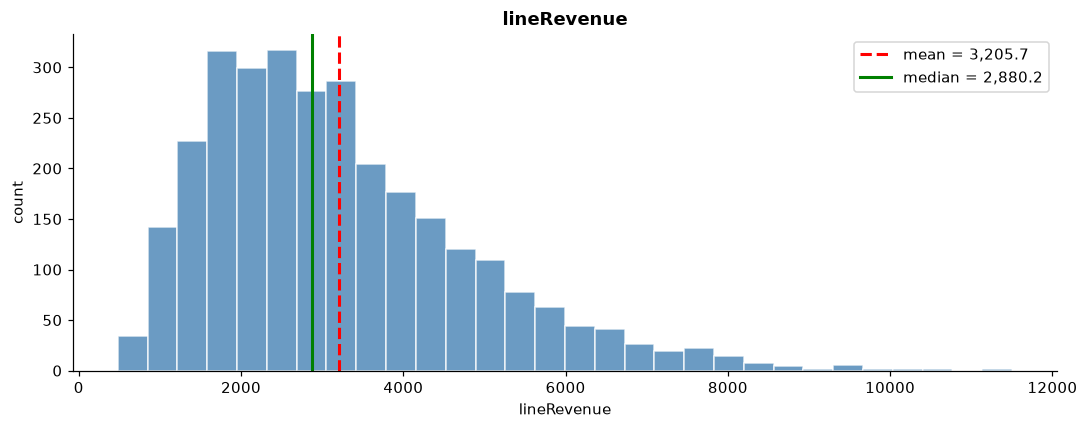

In [109]:
# line revenue 
plot_histogram(df,"lineRevenue")

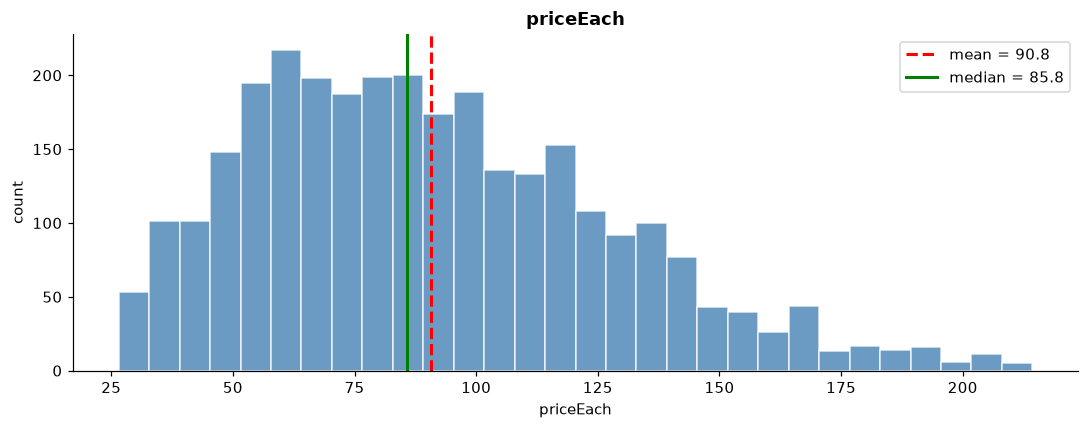

In [110]:
# price each
plot_histogram(df,"priceEach")

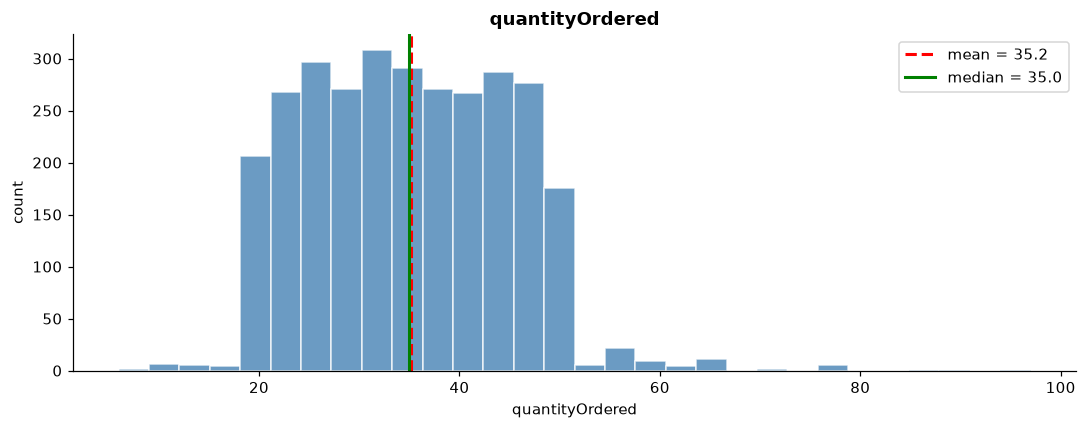

In [111]:
# qauntity ordered
plot_histogram(df,"quantityOrdered")

## Bar chart

In [112]:
# check duplicates của hóa đơn
df.duplicated(subset="orderNumber").sum()

np.int64(2670)

In [113]:
df.head(5)

,orderNumber,orderDate,shippedDate,orderStatus,customerNumber,customerName,customerCountry,customerCity,creditLimit,salesRep,productName,productLine,quantityInStock,quantityOrdered,priceEach,lineRevenue
0,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1917 Grand Touring Sedan,Vintage Cars,2724,30,136.000000,4080.000000
1,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1911 Ford Town Car,Vintage Cars,540,50,55.090000,2754.500000
2,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1932 Alfa Romeo 8C2300 Spider Sport,Vintage Cars,6553,22,75.459999,1660.119995
3,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1936 Mercedes Benz 500k Roadster,Vintage Cars,2081,49,35.290001,1729.209961
4,10101,2003-01-09,2003-01-11,Shipped,128,"Blauer See Auto, Co.",Germany,Frankfurt,59700.0,Barry Jones,1932 Model A Ford J-Coupe,Vintage Cars,9354,25,108.059998,2701.500000


In [114]:
groupby_orderNumber = df.groupby("orderNumber")["lineRevenue"].sum().reset_index().sort_values(by="lineRevenue", ascending=False)
groupby_orderNumber.head(10)

,orderNumber,lineRevenue
65,10165,67392.851562
187,10287,61402.000000
210,10310,61234.671875
112,10212,59830.550781
107,10207,59265.140625
27,10127,58841.351562
104,10204,58793.531250
26,10126,57131.921875
122,10222,56822.652344
42,10142,56052.562500


In [115]:
df.drop_duplicates(subset="orderNumber")

,orderNumber,orderDate,shippedDate,orderStatus,customerNumber,customerName,customerCountry,customerCity,creditLimit,salesRep,productName,productLine,quantityInStock,quantityOrdered,priceEach,lineRevenue
0,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1917 Grand Touring Sedan,Vintage Cars,2724,30,136.000000,4080.000000
4,10101,2003-01-09,2003-01-11,Shipped,128,"Blauer See Auto, Co.",Germany,Frankfurt,59700.0,Barry Jones,1932 Model A Ford J-Coupe,Vintage Cars,9354,25,108.059998,2701.500000
8,10102,2003-01-10,2003-01-14,Shipped,181,Vitachrome Inc.,USA,NYC,76400.0,Foon Yue Tseng,1937 Lincoln Berline,Vintage Cars,8693,39,95.550003,3726.449951
10,10103,2003-01-29,2003-02-02,Shipped,121,Baane Mini Imports,Norway,Stavern,81700.0,Barry Jones,1952 Alpine Renault 1300,Classic Cars,7305,26,214.300003,5571.799805
26,10104,2003-01-31,2003-02-01,Shipped,141,Euro+ Shopping Channel,Spain,Madrid,227600.0,Gerard Hernandez,1969 Corvair Monza,Classic Cars,6906,34,131.440002,4468.959961
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2968,10421,2005-05-29,NaT,In Process,124,Mini Gifts Distributors Ltd.,USA,San Rafael,210500.0,Leslie Jennings,1928 Mercedes-Benz SSK,Vintage Cars,548,35,167.059998,5847.100098
2970,10422,2005-05-30,NaT,In Process,157,Diecast Classics Inc.,USA,Allentown,100600.0,Steve Patterson,1937 Lincoln Berline,Vintage Cars,8693,51,91.440002,4663.439941
2972,10423,2005-05-30,NaT,In Process,314,Petit Auto,Belgium,Bruxelles,79900.0,Pamela Castillo,1913 Ford Model T Speedster,Vintage Cars,4189,10,89.150002,891.500000
2977,10424,2005-05-31,NaT,In Process,141,Euro+ Shopping Channel,Spain,Madrid,227600.0,Gerard Hernandez,1952 Alpine Renault 1300,Classic Cars,7305,50,201.440002,10072.000000


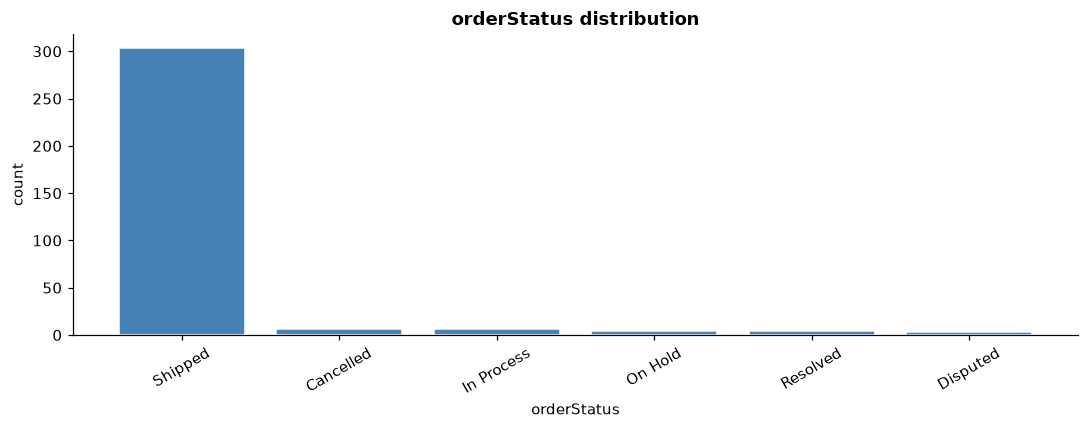

In [116]:
plot_countbar(df.drop_duplicates(subset="orderNumber"), "orderStatus")

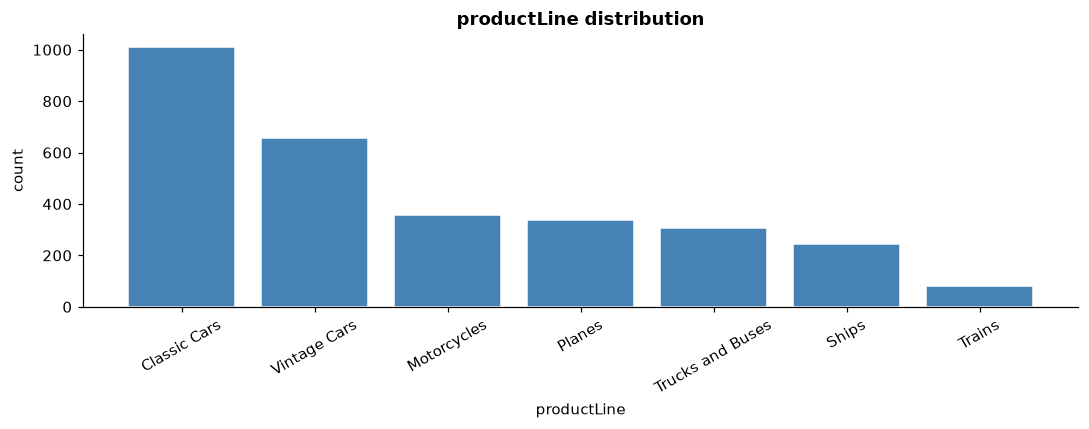

In [117]:
plot_countbar(df, "productLine")

## Line bar

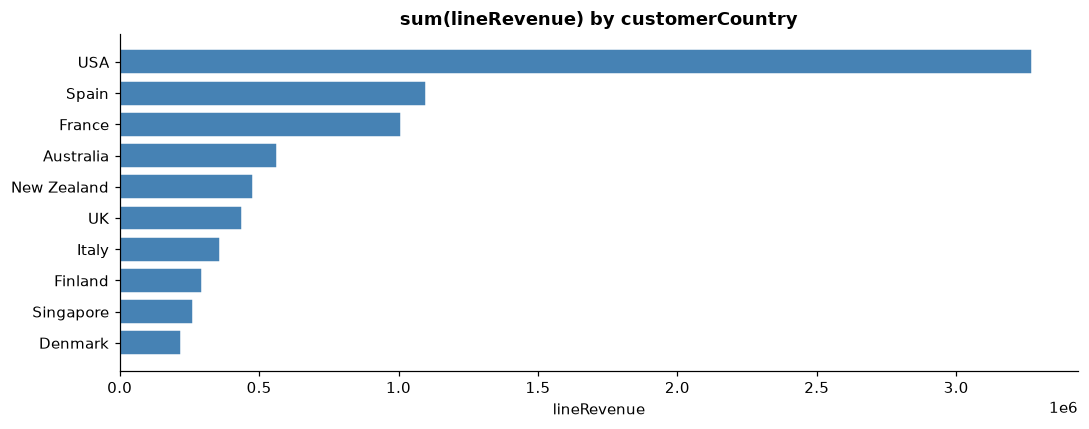

In [118]:
plot_bar(df, "customerCountry", "lineRevenue")

## Phân tích nhị biến

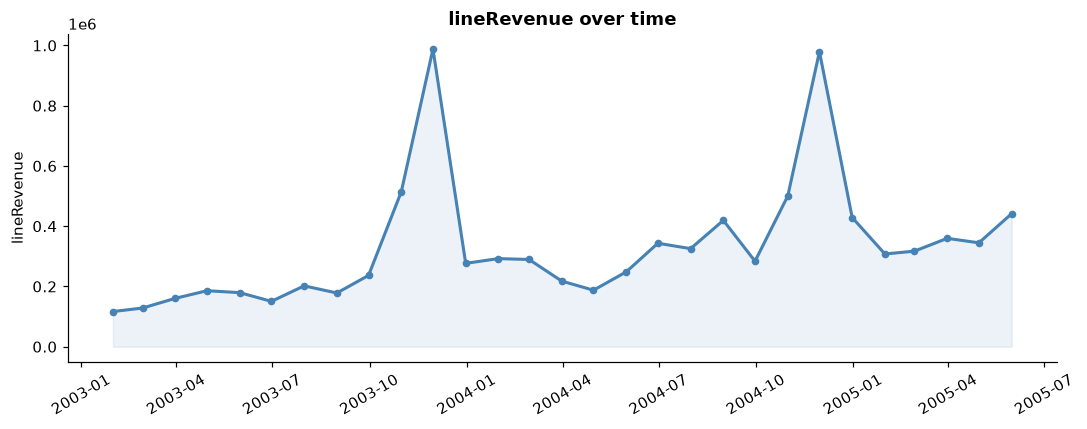

In [119]:
plot_line(df, "orderDate", "lineRevenue", freq="ME")

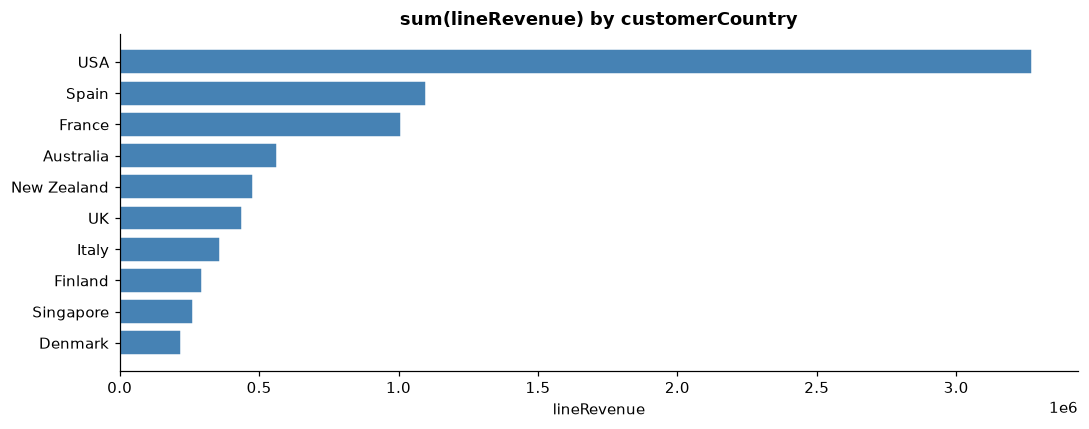

In [120]:
plot_bar(df,"customerCountry","lineRevenue")

In [121]:
df["year"] = df["orderDate"].dt.year
df["month"] = df["orderDate"].dt.month
df["year_month"] = df["orderDate"].dt.to_period("M")
df.head(5)

,orderNumber,orderDate,shippedDate,orderStatus,customerNumber,customerName,customerCountry,customerCity,creditLimit,salesRep,productName,productLine,quantityInStock,quantityOrdered,priceEach,lineRevenue,year,month,year_month
0,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1917 Grand Touring Sedan,Vintage Cars,2724,30,136.000000,4080.000000,2003,1,2003-01
1,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1911 Ford Town Car,Vintage Cars,540,50,55.090000,2754.500000,2003,1,2003-01
2,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1932 Alfa Romeo 8C2300 Spider Sport,Vintage Cars,6553,22,75.459999,1660.119995,2003,1,2003-01
3,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1936 Mercedes Benz 500k Roadster,Vintage Cars,2081,49,35.290001,1729.209961,2003,1,2003-01
4,10101,2003-01-09,2003-01-11,Shipped,128,"Blauer See Auto, Co.",Germany,Frankfurt,59700.0,Barry Jones,1932 Model A Ford J-Coupe,Vintage Cars,9354,25,108.059998,2701.500000,2003,1,2003-01


## Phân tích đa biến

In [122]:
product_overall = df.groupby("productLine").agg(
    TotalRevenue = ("lineRevenue", "sum"),
    TotalQuantity = ("quantityOrdered", "sum"),
    CustomerCount = ("customerNumber", "nunique")
).reset_index()
product_overall

,productLine,TotalRevenue,TotalQuantity,CustomerCount
0,Classic Cars,3.853922e+06,35582,94
1,Motorcycles,1.121426e+06,12778,55
2,Planes,9.546376e+05,11872,52
3,Ships,6.639983e+05,8532,51
4,Trains,1.885329e+05,2818,36
5,Trucks and Buses,1.024114e+06,11001,50
6,Vintage Cars,1.797560e+06,22933,90


In [123]:
df

,orderNumber,orderDate,shippedDate,orderStatus,customerNumber,customerName,customerCountry,customerCity,creditLimit,salesRep,productName,productLine,quantityInStock,quantityOrdered,priceEach,lineRevenue,year,month,year_month
0,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1917 Grand Touring Sedan,Vintage Cars,2724,30,136.000000,4080.000000,2003,1,2003-01
1,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1911 Ford Town Car,Vintage Cars,540,50,55.090000,2754.500000,2003,1,2003-01
2,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1932 Alfa Romeo 8C2300 Spider Sport,Vintage Cars,6553,22,75.459999,1660.119995,2003,1,2003-01
3,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1936 Mercedes Benz 500k Roadster,Vintage Cars,2081,49,35.290001,1729.209961,2003,1,2003-01
4,10101,2003-01-09,2003-01-11,Shipped,128,"Blauer See Auto, Co.",Germany,Frankfurt,59700.0,Barry Jones,1932 Model A Ford J-Coupe,Vintage Cars,9354,25,108.059998,2701.500000,2003,1,2003-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2991,10425,2005-05-31,NaT,In Process,119,La Rochelle Gifts,France,Nantes,118200.0,Gerard Hernandez,1962 Volkswagen Microbus,Trucks and Buses,2327,49,127.790001,6261.709961,2005,5,2005-05
2992,10425,2005-05-31,NaT,In Process,119,La Rochelle Gifts,France,Nantes,118200.0,Gerard Hernandez,1958 Chevy Corvette Limited Edition,Classic Cars,2542,31,31.820000,986.419983,2005,5,2005-05
2993,10425,2005-05-31,NaT,In Process,119,La Rochelle Gifts,France,Nantes,118200.0,Gerard Hernandez,1980’s GM Manhattan Express,Trucks and Buses,5099,41,83.790001,3435.389893,2005,5,2005-05
2994,10425,2005-05-31,NaT,In Process,119,La Rochelle Gifts,France,Nantes,118200.0,Gerard Hernandez,1954 Greyhound Scenicruiser,Trucks and Buses,2874,11,50.320000,553.520020,2005,5,2005-05


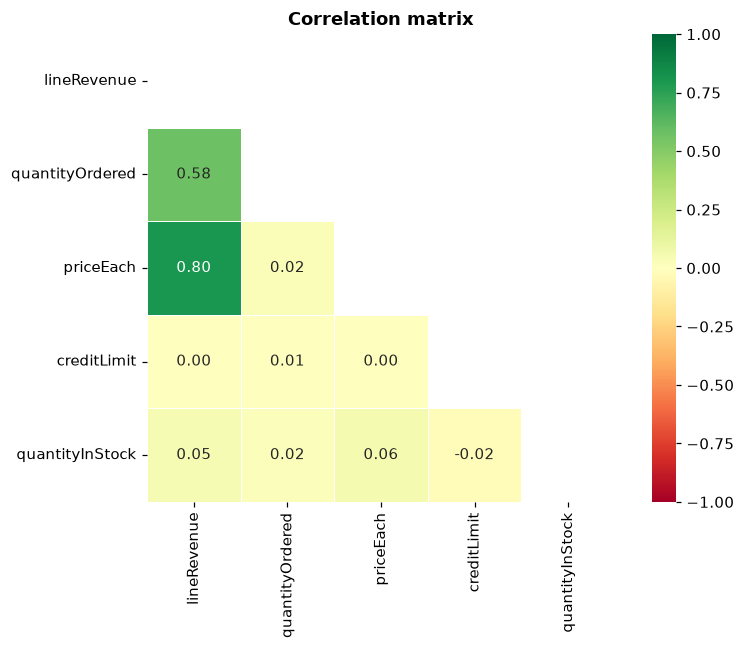

In [124]:
cols = ["lineRevenue", "quantityOrdered", "priceEach","creditLimit", "quantityInStock"]

plot_heatmap_corr(df, cols)

# Outlier


## Detect outlier

In [125]:
col = "lineRevenue"
data_outliers = df[col].dropna()

In [126]:
q1 = data_outliers.quantile(0.25)
q2 = data_outliers.quantile(0.5)
q3 = data_outliers.quantile(0.75)

print(f"Q1 and Q3 is: {q1} and {q3}")

Q1 and Q3 is: 1990.2750244140625 and 4093.9200439453125


In [127]:
IQR = q3 - q1 
lower = q1 - IQR * 1.5 # Gan cuc tieu
upper = q3 + IQR * 1.5 # Gan cuc dai

In [128]:
n_low = (data_outliers < lower).sum()
n_high = (data_outliers > upper).sum()
n_out = n_low + n_high
n_out

np.int64(76)

In [129]:
from utils.outlier import *

In [130]:
detect_outliers(data_outliers)

{'lower': np.float64(-1165.1925048828125),
 'upper': np.float64(7249.3875732421875),
 'mask': 0       False
 1       False
 2       False
 3       False
 4       False
         ...  
 2991    False
 2992    False
 2993    False
 2994    False
 2995    False
 Name: lineRevenue, Length: 2996, dtype: bool,
 'n_out': 76,
 'pct_out': np.float64(2.5)}

In [131]:
outlier_summary(df,["lineRevenue","quantityOrdered","priceEach"])

column                      lower      upper    n_out    pct
------------------------------------------------------------
lineRevenue              -1,165.2    7,249.4       76   2.5%
quantityOrdered               3.0       67.0       10   0.3%
priceEach                   -17.0      193.6       29   1.0%


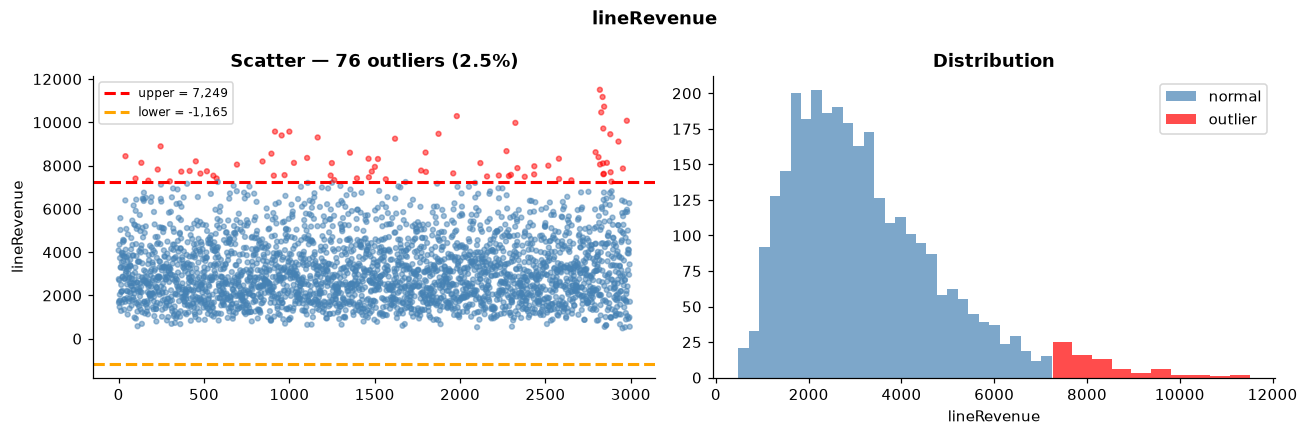

In [133]:
plot_outlier(df, "lineRevenue")

In [135]:
df.loc[df["lineRevenue"] > upper]

,orderNumber,orderDate,shippedDate,orderStatus,customerNumber,customerName,customerCountry,customerCity,creditLimit,salesRep,productName,productLine,quantityInStock,quantityOrdered,priceEach,lineRevenue,year,month,year_month
40,10105,2003-02-11,2003-02-12,Shipped,145,Danish Wholesale Imports,Denmark,Kobenhavn,83400.0,Pamela Castillo,2001 Ferrari Enzo,Classic Cars,3619,41,205.720001,8434.519531,2003,2,2003-02
99,10109,2003-03-10,2003-03-11,Shipped,486,Motor Mint Distributors Inc.,USA,Philadelphia,72600.0,George Vanauf,1992 Ferrari 360 Spider red,Classic Cars,8347,46,160.869995,7400.020020,2003,3,2003-03
133,10114,2003-04-01,2003-04-02,Shipped,172,"La Corne D'abondance, Co.",France,Paris,84300.0,Loui Bondur,1992 Ferrari 360 Spider red,Classic Cars,8347,48,169.339996,8128.319824,2003,4,2003-04
174,10120,2003-04-29,2003-05-01,Shipped,114,"Australian Collectors, Co.",Australia,Melbourne,117300.0,Andy Fixter,2003 Harley-Davidson Eagle Drag Bike,Motorcycles,5582,46,158.800003,7304.799805,2003,4,2003-04
229,10126,2003-05-28,2003-06-02,Shipped,458,"Corrida Auto Replicas, Ltd",Spain,Madrid,104600.0,Martin Gerard,1952 Alpine Renault 1300,Classic Cars,7305,38,205.729996,7817.740234,2003,5,2003-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2882,10412,2005-05-03,2005-05-05,Shipped,141,Euro+ Shopping Channel,Spain,Madrid,227600.0,Gerard Hernandez,1962 Volkswagen Microbus,Trucks and Buses,2327,70,109.900002,7693.000000,2005,5,2005-05
2887,10413,2005-05-05,2005-05-09,Shipped,175,Gift Depot Inc.,USA,Bridgewater,84300.0,George Vanauf,2001 Ferrari Enzo,Classic Cars,3619,36,201.570007,7256.520020,2005,5,2005-05
2928,10417,2005-05-13,2005-05-19,Disputed,141,Euro+ Shopping Channel,Spain,Madrid,227600.0,Gerard Hernandez,2003 Harley-Davidson Eagle Drag Bike,Motorcycles,5582,56,162.669998,9109.519531,2005,5,2005-05
2954,10419,2005-05-17,2005-05-19,Shipped,382,Salzburg Collectables,Austria,Salzburg,71700.0,Pamela Castillo,1956 Porsche 356A Coupe,Classic Cars,6600,70,112.339996,7863.799805,2005,5,2005-05


## Xu li outlier

In [138]:
# Xoa outlier
df_new = df.loc[df["lineRevenue"] <= upper]
df_new

,orderNumber,orderDate,shippedDate,orderStatus,customerNumber,customerName,customerCountry,customerCity,creditLimit,salesRep,productName,productLine,quantityInStock,quantityOrdered,priceEach,lineRevenue,year,month,year_month
0,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1917 Grand Touring Sedan,Vintage Cars,2724,30,136.000000,4080.000000,2003,1,2003-01
1,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1911 Ford Town Car,Vintage Cars,540,50,55.090000,2754.500000,2003,1,2003-01
2,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1932 Alfa Romeo 8C2300 Spider Sport,Vintage Cars,6553,22,75.459999,1660.119995,2003,1,2003-01
3,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1936 Mercedes Benz 500k Roadster,Vintage Cars,2081,49,35.290001,1729.209961,2003,1,2003-01
4,10101,2003-01-09,2003-01-11,Shipped,128,"Blauer See Auto, Co.",Germany,Frankfurt,59700.0,Barry Jones,1932 Model A Ford J-Coupe,Vintage Cars,9354,25,108.059998,2701.500000,2003,1,2003-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2991,10425,2005-05-31,NaT,In Process,119,La Rochelle Gifts,France,Nantes,118200.0,Gerard Hernandez,1962 Volkswagen Microbus,Trucks and Buses,2327,49,127.790001,6261.709961,2005,5,2005-05
2992,10425,2005-05-31,NaT,In Process,119,La Rochelle Gifts,France,Nantes,118200.0,Gerard Hernandez,1958 Chevy Corvette Limited Edition,Classic Cars,2542,31,31.820000,986.419983,2005,5,2005-05
2993,10425,2005-05-31,NaT,In Process,119,La Rochelle Gifts,France,Nantes,118200.0,Gerard Hernandez,1980’s GM Manhattan Express,Trucks and Buses,5099,41,83.790001,3435.389893,2005,5,2005-05
2994,10425,2005-05-31,NaT,In Process,119,La Rochelle Gifts,France,Nantes,118200.0,Gerard Hernandez,1954 Greyhound Scenicruiser,Trucks and Buses,2874,11,50.320000,553.520020,2005,5,2005-05


In [139]:
# Capping outlier
cap_outliers(df,["lineRevenue"])

column                   before_max    after_max  n_changed
------------------------------------------------------------
lineRevenue                11,503.1      7,249.4         76

Row count unchanged: 2,996


,orderNumber,orderDate,shippedDate,orderStatus,customerNumber,customerName,customerCountry,customerCity,creditLimit,salesRep,productName,productLine,quantityInStock,quantityOrdered,priceEach,lineRevenue,year,month,year_month
0,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1917 Grand Touring Sedan,Vintage Cars,2724,30,136.000000,4080.000000,2003,1,2003-01
1,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1911 Ford Town Car,Vintage Cars,540,50,55.090000,2754.500000,2003,1,2003-01
2,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1932 Alfa Romeo 8C2300 Spider Sport,Vintage Cars,6553,22,75.459999,1660.119995,2003,1,2003-01
3,10100,2003-01-06,2003-01-10,Shipped,363,Online Diecast Creations Co.,USA,Nashua,114200.0,Steve Patterson,1936 Mercedes Benz 500k Roadster,Vintage Cars,2081,49,35.290001,1729.209961,2003,1,2003-01
4,10101,2003-01-09,2003-01-11,Shipped,128,"Blauer See Auto, Co.",Germany,Frankfurt,59700.0,Barry Jones,1932 Model A Ford J-Coupe,Vintage Cars,9354,25,108.059998,2701.500000,2003,1,2003-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2991,10425,2005-05-31,NaT,In Process,119,La Rochelle Gifts,France,Nantes,118200.0,Gerard Hernandez,1962 Volkswagen Microbus,Trucks and Buses,2327,49,127.790001,6261.709961,2005,5,2005-05
2992,10425,2005-05-31,NaT,In Process,119,La Rochelle Gifts,France,Nantes,118200.0,Gerard Hernandez,1958 Chevy Corvette Limited Edition,Classic Cars,2542,31,31.820000,986.419983,2005,5,2005-05
2993,10425,2005-05-31,NaT,In Process,119,La Rochelle Gifts,France,Nantes,118200.0,Gerard Hernandez,1980’s GM Manhattan Express,Trucks and Buses,5099,41,83.790001,3435.389893,2005,5,2005-05
2994,10425,2005-05-31,NaT,In Process,119,La Rochelle Gifts,France,Nantes,118200.0,Gerard Hernandez,1954 Greyhound Scenicruiser,Trucks and Buses,2874,11,50.320000,553.520020,2005,5,2005-05
